# Smart Irrigation System Using Mamdani Fuzzy Logic

## 1. Objective
To estimate irrigation demand using a Mamdani fuzzy inference system based on soil moisture and temperature.

## 2. Inputs
- Soil moisture: 0–100%
- Temperature: 0–45°C

## 3. Output
- Irrigation demand: 0–100 normalized score

## 4. Methodology
1. Define fuzzy membership functions.
2. Fuzzify the input values.
3. Apply the fuzzy rule base.
4. Aggregate the rule outputs.
5. Defuzzify using the centroid method.
6. Compare the result with a simple threshold-based baseline.

## 5. Scope and assumptions
This is a software simulation, not a real irrigation controller. The output is a normalized demand score, not litres of water or pump runtime. Membership functions and rules are prototype assumptions and would require agricultural calibration before real-world use.


In [ ]:
# Check our Python environment
import sys

print("Python version:", sys.version)
print("Project setup started successfully!")

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Project setup started successfully!


In [ ]:
%pip install numpy matplotlib

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# Input ranges
MOISTURE_MIN, MOISTURE_MAX = 0.0, 100.0
TEMPERATURE_MIN, TEMPERATURE_MAX = 0.0, 45.0
DEMAND_MIN, DEMAND_MAX = 0.0, 100.0
# Output range
DEMAND_MIN = 0
DEMAND_MAX = 100

# Grids used for plotting and whole-domain coverage tests.
# Keep these names distinct from the single user-entered values below.
moisture_grid = np.linspace(MOISTURE_MIN, MOISTURE_MAX, 501)
temperature_grid = np.linspace(TEMPERATURE_MIN, TEMPERATURE_MAX, 451)
demand_grid = np.linspace(DEMAND_MIN, DEMAND_MAX, 501)

In [ ]:
# production-ready, cleaner, modular, and built specifically to plug into automated testing frameworks and fuzzy inference rule engines (like the Phase 1 script we worked on).
# Membership-function helpers

def trimf(x, a, b, c):
    # Triangular membership function; requires a < b < c.
    if not a < b < c:
        raise ValueError("Triangle parameters must satisfy a < b < c.")
    x = np.asarray(x, dtype=float)
    rising = (x - a) / (b - a)
    falling = (c - x) / (c - b)
    return np.clip(np.minimum(rising, falling), 0.0, 1.0)


def left_shoulder(x, a, b):
    # Left-shoulder function: membership is 1 at/below a and 0 at/above b.
    if not a < b:
        raise ValueError("Left-shoulder parameters must satisfy a < b.")
    x = np.asarray(x, dtype=float)
    return np.clip((b - x) / (b - a), 0.0, 1.0)


def right_shoulder(x, a, b):
    # Right-shoulder function: membership is 0 at/below a and 1 at/above b.
    if not a < b:
        raise ValueError("Right-shoulder parameters must satisfy a < b.")
    x = np.asarray(x, dtype=float)
    return np.clip((x - a) / (b - a), 0.0, 1.0)


# Centralized parameters: define them once and reuse them in plots, tests and fuzzification.
DRY_PARAMS = (20.0, 50.0)
MODERATE_MOISTURE_PARAMS = (20.0, 50.0, 80.0)
WET_PARAMS = (50.0, 80.0)

COOL_PARAMS = (10.0, 22.5)
WARM_PARAMS = (10.0, 22.5, 35.0)
HOT_PARAMS = (22.5, 35.0)

NO_DEMAND_PARAMS = (0.0, 25.0)
LOW_DEMAND_PARAMS = (0.0, 25.0, 50.0)
MEDIUM_DEMAND_PARAMS = (25.0, 50.0, 75.0)
HIGH_DEMAND_PARAMS = (50.0, 75.0)

# Membership functions (these are functions; the arrays below are their sampled curves).
moisture_mfs = {
    "Dry": lambda x: left_shoulder(x, *DRY_PARAMS),
    "Moderate": lambda x: trimf(x, *MODERATE_MOISTURE_PARAMS),
    "Wet": lambda x: right_shoulder(x, *WET_PARAMS),
}

temperature_mfs = {
    "Cool": lambda x: left_shoulder(x, *COOL_PARAMS),
    "Warm": lambda x: trimf(x, *WARM_PARAMS),
    "Hot": lambda x: right_shoulder(x, *HOT_PARAMS),
}

demand_mfs = {
    "None": lambda x: left_shoulder(x, *NO_DEMAND_PARAMS),
    "Low": lambda x: trimf(x, *LOW_DEMAND_PARAMS),
    "Medium": lambda x: trimf(x, *MEDIUM_DEMAND_PARAMS),
    "High": lambda x: right_shoulder(x, *HIGH_DEMAND_PARAMS),
}

# Sample every membership function over its full domain.
moisture_sets = {name: mf(moisture_grid) for name, mf in moisture_mfs.items()}
temperature_sets = {name: mf(temperature_grid) for name, mf in temperature_mfs.items()}
demand_sets = {name: mf(demand_grid) for name, mf in demand_mfs.items()}

# General fuzzification helper for a single crisp value.
def fuzzify(membership_functions, value):
    return {name: float(mf(value)) for name, mf in membership_functions.items()}

print("Membership functions defined and sampled.")

Membership functions defined and sampled.


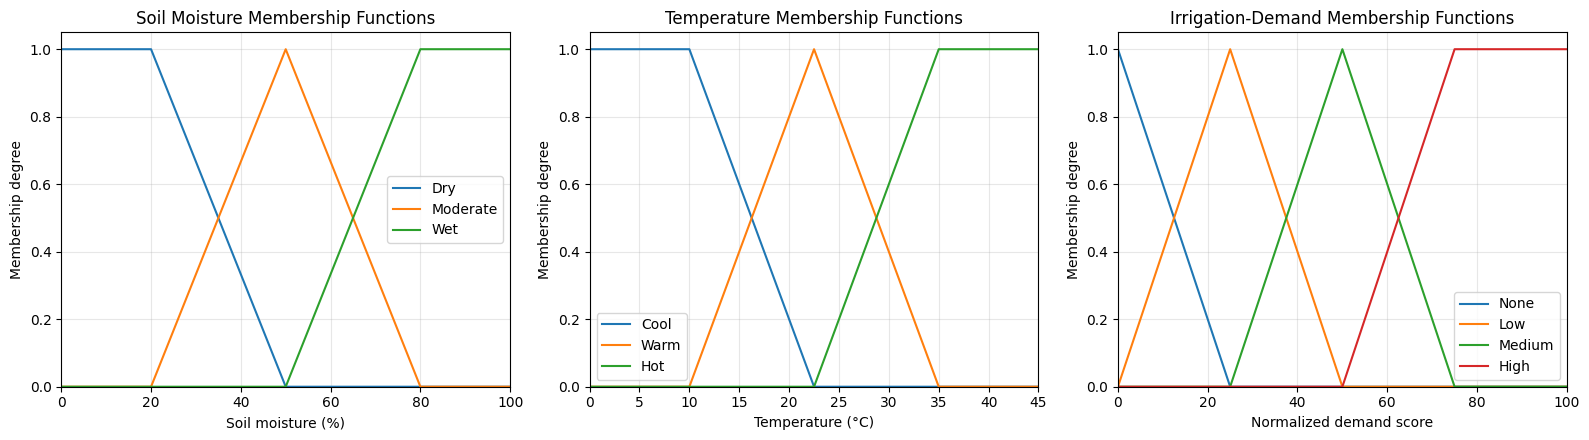

In [ ]:
# Plot the membership functions generated from the same functions used by the model.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for name, values in moisture_sets.items():
    axes[0].plot(moisture_grid, values, label=name)
axes[0].set_title("Soil Moisture Membership Functions")
axes[0].set_xlabel("Soil moisture (%)")
axes[0].set_ylabel("Membership degree")
axes[0].set_xlim(MOISTURE_MIN, MOISTURE_MAX)
axes[0].set_ylim(0, 1.05)
axes[0].legend()
axes[0].grid(True, alpha=0.3)

for name, values in temperature_sets.items():
    axes[1].plot(temperature_grid, values, label=name)
axes[1].set_title("Temperature Membership Functions")
axes[1].set_xlabel("Temperature (°C)")
axes[1].set_ylabel("Membership degree")
axes[1].set_xlim(TEMPERATURE_MIN, TEMPERATURE_MAX)
axes[1].set_ylim(0, 1.05)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

for name, values in demand_sets.items():
    axes[2].plot(demand_grid, values, label=name)
axes[2].set_title("Irrigation-Demand Membership Functions")
axes[2].set_xlabel("Normalized demand score")
axes[2].set_ylabel("Membership degree")
axes[2].set_xlim(DEMAND_MIN, DEMAND_MAX)
axes[2].set_ylim(0, 1.05)
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
def parse_bounded_float(raw_value, name, lower, upper):
    """Convert an input to a finite float and enforce its permitted range."""
    try:
        value = float(raw_value)
    except (TypeError, ValueError) as exc:
        raise ValueError(f"{name} must be a number.") from exc

    if not np.isfinite(value):
        raise ValueError(f"{name} must be a finite number.")
    if not lower <= value <= upper:
        raise ValueError(f"{name} must be between {lower:g} and {upper:g}.")
    return value


def read_bounded_float(prompt, name, lower, upper):
    """Keep prompting until the user enters a valid value in range."""
    while True:
        raw_value = input(prompt)
        try:
            return parse_bounded_float(raw_value, name, lower, upper)
        except ValueError as error:
            print(error, "Please try again.")


# User-entered scalar values have distinct names from the domain grids.
soil_moisture_input = read_bounded_float(
    "Enter soil moisture (0-100%): ", "Soil moisture", MOISTURE_MIN, MOISTURE_MAX
)
temperature_input = read_bounded_float(
    "Enter temperature (0-45°C): ", "Temperature", TEMPERATURE_MIN, TEMPERATURE_MAX
)

moisture_input_memberships = fuzzify(moisture_mfs, soil_moisture_input)
temperature_input_memberships = fuzzify(temperature_mfs, temperature_input)

print("\n--- Fuzzified inputs ---")
print(f"Soil moisture: {soil_moisture_input:.2f}%")
for name, degree in moisture_input_memberships.items():
    print(f"  {name}: {degree:.3f}")

print(f"Temperature: {temperature_input:.2f}°C")
for name, degree in temperature_input_memberships.items():
    print(f"  {name}: {degree:.3f}")

Enter soil moisture (0-100%): 34
Enter temperature (0-45°C): 33

--- Fuzzified inputs ---
Soil moisture: 34.00%
  Dry: 0.533
  Moderate: 0.467
  Wet: 0.000
Temperature: 33.00°C
  Cool: 0.000
  Warm: 0.160
  Hot: 0.840


In [ ]:
# Verify the triangular membership calculations by hand for the current input values.
def triangle_membership_by_hand(x, a, b, c):
    """Piecewise formula for a triangle, used only for independent verification."""
    if not a < b < c:
        raise ValueError("Triangle parameters must satisfy a < b < c.")
    if x <= a or x >= c:
        return 0.0
    if x == b:
        return 1.0
    if x < b:
        return (x - a) / (b - a)
    return (c - x) / (c - b)


hand_moisture = triangle_membership_by_hand(
    soil_moisture_input, *MODERATE_MOISTURE_PARAMS
)
python_moisture = float(moisture_mfs["Moderate"](soil_moisture_input))

hand_temperature = triangle_membership_by_hand(temperature_input, *WARM_PARAMS)
python_temperature = float(temperature_mfs["Warm"](temperature_input))

print(f"Moderate moisture membership — hand: {hand_moisture:.3f}, Python: {python_moisture:.3f}")
print(f"Warm temperature membership — hand: {hand_temperature:.3f}, Python: {python_temperature:.3f}")

assert np.isclose(hand_moisture, python_moisture)
assert np.isclose(hand_temperature, python_temperature)
print("Hand calculations agree with Python.")

Moderate moisture membership — hand: 0.467, Python: 0.467
Warm temperature membership — hand: 0.160, Python: 0.160
Hand calculations agree with Python.


In [ ]:
# Boundary tests: expected values are ordered according to each membership-function dictionary.
tests = [
    ("Moisture", 0,     [1, 0, 0]),
    ("Moisture", 20,    [1, 0, 0]),
    ("Moisture", 50,    [0, 1, 0]),
    ("Moisture", 80,    [0, 0, 1]),
    ("Moisture", 100,   [0, 0, 1]),
    ("Temperature", 0,  [1, 0, 0]),
    ("Temperature", 10, [1, 0, 0]),
    ("Temperature", 22.5, [0, 1, 0]),
    ("Temperature", 35, [0, 0, 1]),
    ("Temperature", 45, [0, 0, 1]),
    ("Demand", 0,       [1, 0, 0, 0]),
    ("Demand", 25,      [0, 1, 0, 0]),
    ("Demand", 50,      [0, 0, 1, 0]),
    ("Demand", 75,      [0, 0, 0, 1]),
    ("Demand", 100,     [0, 0, 0, 1]),
]

function_groups = {
    "Moisture": moisture_mfs,
    "Temperature": temperature_mfs,
    "Demand": demand_mfs,
}

for category, value, expected in tests:
    actual_dict = fuzzify(function_groups[category], value)
    actual = list(actual_dict.values())
    assert np.allclose(actual, expected), (
        f"{category} boundary test failed at {value}: "
        f"expected {expected}, got {actual}"
    )

print(f"All {len(tests)} membership boundary tests passed.")

All 15 membership boundary tests passed.


In [ ]:
# Check full-domain coverage. This uses the grid arrays, not the user's single input value.
def check_domain_coverage(name, membership_sets, grid):
    matrix = np.vstack(list(membership_sets.values()))

    assert matrix.shape[1] == len(grid), (
        f"{name}: membership arrays must match the full grid length."
    )
    assert np.all(np.isfinite(matrix)), f"{name}: non-finite membership value found."
    assert np.all((matrix >= 0.0) & (matrix <= 1.0)), (
        f"{name}: membership values must remain in [0, 1]."
    )

    covered = np.any(matrix > 0.0, axis=0)
    uncovered_points = grid[~covered]
    print(f"{name}: full domain covered = {bool(np.all(covered))}")
    assert np.all(covered), f"{name}: uncovered points: {uncovered_points[:10]}"


check_domain_coverage("Soil moisture", moisture_sets, moisture_grid)
check_domain_coverage("Temperature", temperature_sets, temperature_grid)
check_domain_coverage("Irrigation demand", demand_sets, demand_grid)
print("All full-domain coverage and membership-range checks passed.")

Soil moisture: full domain covered = True
Temperature: full domain covered = True
Irrigation demand: full domain covered = True
All full-domain coverage and membership-range checks passed.


In [ ]:
# Phase 2: define the nine fuzzy IF-THEN rules.
# Each tuple is: (rule ID, moisture category, temperature category, Irrigation Demand Consequent).
RULE_BASE = [
    ("R1", "Dry",      "Cool", "Medium"),
    ("R2", "Dry",      "Warm", "High"),
    ("R3", "Dry",      "Hot",  "High"),
    ("R4", "Moderate", "Cool", "Low"),
    ("R5", "Moderate", "Warm", "Medium"),
    ("R6", "Moderate", "Hot",  "Medium"),
    ("R7", "Wet",      "Cool", "None"),
    ("R8", "Wet",      "Warm", "None"),
    ("R9", "Wet",      "Hot",  "Low"),
]


def validate_rule_base(rule_base):
    """Check that all nine input-category combinations appear exactly once."""
    expected_pairs = {
        (moisture_name, temperature_name)
        for moisture_name in moisture_mfs
        for temperature_name in temperature_mfs
    }
    actual_pairs = [(rule[1], rule[2]) for rule in rule_base]

    assert len(rule_base) == 9, "The current design must contain nine rules."
    assert len(set(actual_pairs)) == len(actual_pairs), "Duplicate antecedent combination found."
    assert set(actual_pairs) == expected_pairs, "A rule combination is missing or invalid."
    assert all(rule[3] in demand_mfs for rule in rule_base), "Unknown demand consequent found."
    assert len({rule[0] for rule in rule_base}) == len(rule_base), "Rule IDs must be unique."


validate_rule_base(RULE_BASE)
print(f"Rule-base validation passed: {len(RULE_BASE)} unique rules cover all 3 × 3 input combinations.")


Rule-base validation passed: 9 unique rules cover all 3 × 3 input combinations.


In [ ]:
def evaluate_rule_strengths(moisture_memberships, temperature_memberships):
    """Return rule firing strengths using min as the fuzzy AND operator.

    The result records input degrees and the rule's output label for diagnostics.
    It does not perform implication, aggregation, or defuzzification.
    """
    results = []

    for rule_id, moisture_term, temperature_term, demand_term in RULE_BASE:
        moisture_degree = float(moisture_memberships[moisture_term])
        temperature_degree = float(temperature_memberships[temperature_term])

        # Mamdani antecedent conjunction for this project: AND = minimum.
        firing_strength = min(moisture_degree, temperature_degree)

        if not (0.0 <= moisture_degree <= 1.0 and 0.0 <= temperature_degree <= 1.0):
            raise ValueError("Membership degrees must lie between 0 and 1.")

        results.append({
            "rule_id": rule_id,
            "moisture_term": moisture_term,
            "moisture_degree": moisture_degree,
            "temperature_term": temperature_term,
            "temperature_degree": temperature_degree,
            "demand_term": demand_term,
            "firing_strength": firing_strength,
        })

    return results


def print_rule_trace(results):
    """Print a readable trace of all rules and their firing strengths."""
    print("\n--- Rule firing-strength trace ---")
    print("Rule | Moisture term (degree) | Temperature term (degree) | Consequent | Strength")
    print("-" * 88)
    for result in results:
        print(
            f"{result['rule_id']:<3}  | "
            f"{result['moisture_term']:<8} ({result['moisture_degree']:.3f}) | "
            f"{result['temperature_term']:<5} ({result['temperature_degree']:.3f}) | "
            f"{result['demand_term']:<8} | {result['firing_strength']:.3f}"
        )


# Evaluate all nine rules for the user-entered readings from Phase 1.
rule_results = evaluate_rule_strengths(
    moisture_input_memberships,
    temperature_input_memberships,
)
print_rule_trace(rule_results)



--- Rule firing-strength trace ---
Rule | Moisture term (degree) | Temperature term (degree) | Consequent | Strength
----------------------------------------------------------------------------------------
R1   | Dry      (0.533) | Cool  (0.000) | Medium   | 0.000
R2   | Dry      (0.533) | Warm  (0.160) | High     | 0.160
R3   | Dry      (0.533) | Hot   (0.840) | High     | 0.533
R4   | Moderate (0.467) | Cool  (0.000) | Low      | 0.000
R5   | Moderate (0.467) | Warm  (0.160) | Medium   | 0.160
R6   | Moderate (0.467) | Hot   (0.840) | Medium   | 0.467
R7   | Wet      (0.000) | Cool  (0.000) | None     | 0.000
R8   | Wet      (0.000) | Warm  (0.160) | None     | 0.000
R9   | Wet      (0.000) | Hot   (0.840) | Low      | 0.000


In [ ]:
# Phase 2 tests: validate rule strengths and independently check a worked example.
assert len(rule_results) == 9
assert all(0.0 <= row["firing_strength"] <= 1.0 for row in rule_results)

# Worked example chosen for reproducible, hand-checkable calculations:
# soil moisture = 45%, temperature = 20°C.
example_moisture_memberships = fuzzify(moisture_mfs, 45.0)
example_temperature_memberships = fuzzify(temperature_mfs, 20.0)
example_results = evaluate_rule_strengths(
    example_moisture_memberships,
    example_temperature_memberships,
)
example_strengths = {row["rule_id"]: row["firing_strength"] for row in example_results}

# At 45% moisture: Dry = (50 - 45) / (50 - 20) = 1/6; Moderate = (45 - 20)/(50 - 20) = 5/6.
# At 20°C: Cool = (22.5 - 20)/(22.5 - 10) = 0.2; Warm = (20 - 10)/(22.5 - 10) = 0.8.
expected_strengths = {
    "R1": 1.0 / 6.0,
    "R2": 1.0 / 6.0,
    "R3": 0.0,
    "R4": 0.2,
    "R5": 0.8,
    "R6": 0.0,
    "R7": 0.0,
    "R8": 0.0,
    "R9": 0.0,
}
for rule_id, expected_strength in expected_strengths.items():
    assert np.isclose(example_strengths[rule_id], expected_strength), (
        f"{rule_id} expected {expected_strength}, got {example_strengths[rule_id]}"
    )

print("All Phase 2 tests passed.")
print("Worked example: soil moisture = 45%, temperature = 20°C")
print_rule_trace(example_results)


All Phase 2 tests passed.
Worked example: soil moisture = 45%, temperature = 20°C

--- Rule firing-strength trace ---
Rule | Moisture term (degree) | Temperature term (degree) | Consequent | Strength
----------------------------------------------------------------------------------------
R1   | Dry      (0.167) | Cool  (0.200) | Medium   | 0.167
R2   | Dry      (0.167) | Warm  (0.800) | High     | 0.167
R3   | Dry      (0.167) | Hot   (0.000) | High     | 0.000
R4   | Moderate (0.833) | Cool  (0.200) | Low      | 0.200
R5   | Moderate (0.833) | Warm  (0.800) | Medium   | 0.800
R6   | Moderate (0.833) | Hot   (0.000) | Medium   | 0.000
R7   | Wet      (0.000) | Cool  (0.200) | None     | 0.000
R8   | Wet      (0.000) | Warm  (0.800) | None     | 0.000
R9   | Wet      (0.000) | Hot   (0.000) | Low      | 0.000


In [ ]:
#Phase 3 — Mamdani Implication and Maximum Aggregation


--- Mamdani implication summary ---
Rule | Consequent | Firing strength / clipping height
---------------------------------------------------------
R1   | Medium     | 0.000
R2   | High       | 0.160
R3   | High       | 0.533
R4   | Low        | 0.000
R5   | Medium     | 0.160
R6   | Medium     | 0.467
R7   | None       | 0.000
R8   | None       | 0.000
R9   | Low        | 0.000
Aggregated output membership range: min=0.000, max=0.533


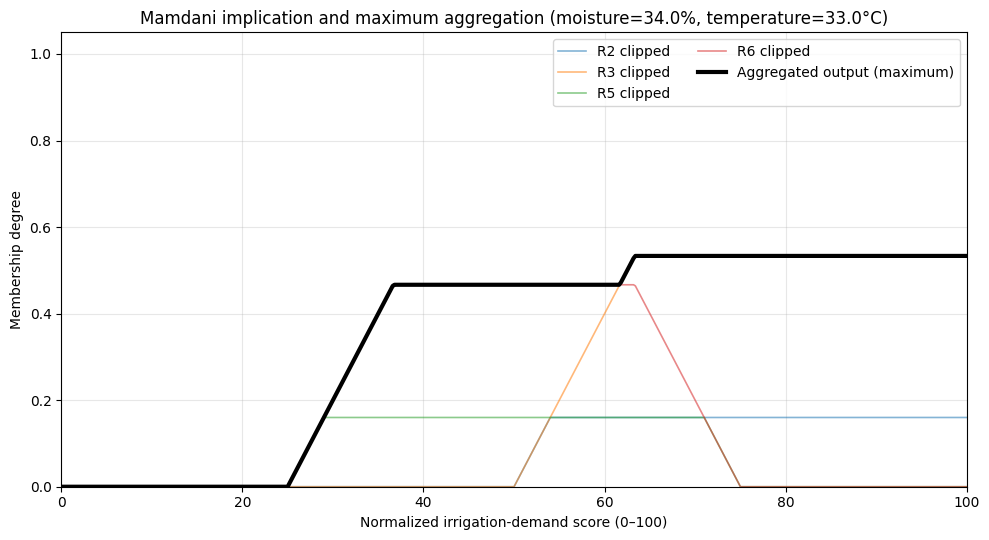

Active clipped rule curves shown: 4 of 9


In [ ]:
# Phase 3: Mamdani implication and maximum aggregation.


def apply_mamdani_implication(rule_results, consequent_sets, output_grid):
    """Clip each rule's consequent membership function at its firing strength.

    Parameters
    ----------
    rule_results : list[dict]
        Output from evaluate_rule_strengths(...).
    consequent_sets : dict[str, np.ndarray]
        Sampled output membership functions, e.g. demand_sets.
    output_grid : np.ndarray
        The grid used to sample the output membership functions.

    Returns
    -------
    dict[str, np.ndarray]
        One clipped membership curve per rule ID.
    """
    if not rule_results:
        raise ValueError("At least one rule result is required.")

    output_grid = np.asarray(output_grid, dtype=float)
    clipped_outputs = {}

    for result in rule_results:
        rule_id = result["rule_id"]
        consequent = result["demand_term"]
        strength = float(result["firing_strength"])

        if rule_id in clipped_outputs:
            raise ValueError(f"Duplicate rule ID: {rule_id}")
        if consequent not in consequent_sets:
            raise ValueError(f"Unknown consequent set: {consequent}")
        if not np.isfinite(strength) or not 0.0 <= strength <= 1.0:
            raise ValueError(f"Invalid firing strength for {rule_id}: {strength}")

        membership_curve = np.asarray(consequent_sets[consequent], dtype=float)
        if membership_curve.shape != output_grid.shape:
            raise ValueError(
                f"Output membership curve for {consequent} must match output_grid shape."
            )
        if not np.all(np.isfinite(membership_curve)):
            raise ValueError(f"Non-finite values found in consequent set {consequent}.")
        if np.any((membership_curve < 0.0) | (membership_curve > 1.0)):
            raise ValueError(f"Membership values for {consequent} must lie in [0, 1].")

        # Mamdani minimum implication: cap the consequent curve at the rule strength.
        clipped_outputs[rule_id] = np.minimum(strength, membership_curve)

    return clipped_outputs


def aggregate_rule_outputs(clipped_rule_outputs):
    """Aggregate individual clipped rule outputs using pointwise maximum."""
    if not clipped_rule_outputs:
        raise ValueError("No clipped rule outputs were supplied for aggregation.")

    curves = [np.asarray(curve, dtype=float) for curve in clipped_rule_outputs.values()]
    expected_shape = curves[0].shape
    if any(curve.shape != expected_shape for curve in curves):
        raise ValueError("All clipped output curves must have the same shape.")

    matrix = np.vstack(curves)
    if not np.all(np.isfinite(matrix)):
        raise ValueError("Clipped output curves contain non-finite values.")
    if np.any((matrix < 0.0) | (matrix > 1.0)):
        raise ValueError("Clipped output membership degrees must lie in [0, 1].")

    # Maximum aggregation: at every output-grid point, keep the largest degree.
    return np.max(matrix, axis=0)


def print_implication_summary(rule_results):
    """Print each rule's consequent and the height at which it is clipped."""
    print("\n--- Mamdani implication summary ---")
    print("Rule | Consequent | Firing strength / clipping height")
    print("-" * 57)
    for result in rule_results:
        print(
            f"{result['rule_id']:<4} | {result['demand_term']:<10} | "
            f"{result['firing_strength']:.3f}"
        )


def plot_aggregated_output(output_grid, clipped_rule_outputs, aggregated_output, title):
    """Plot active clipped rule curves and their maximum-aggregated envelope."""
    plt.figure(figsize=(10, 5.5))
    active_count = 0
    for rule_id, curve in clipped_rule_outputs.items():
        if np.any(curve > 0.0):
            plt.plot(output_grid, curve, linewidth=1.2, alpha=0.55, label=f"{rule_id} clipped")
            active_count += 1

    plt.plot(
        output_grid, aggregated_output,
        linewidth=3.0, color="black", label="Aggregated output (maximum)"
    )
    plt.title(title)
    plt.xlabel("Normalized irrigation-demand score (0–100)")
    plt.ylabel("Membership degree")
    plt.xlim(DEMAND_MIN, DEMAND_MAX)
    plt.ylim(0.0, 1.05)
    plt.grid(True, alpha=0.3)
    plt.legend(ncol=2)
    plt.tight_layout()
    plt.show()
    print(f"Active clipped rule curves shown: {active_count} of {len(clipped_rule_outputs)}")


# Apply Phase 3 to the user-entered input processed in Phases 1–2.
clipped_rule_outputs = apply_mamdani_implication(
    rule_results, demand_sets, demand_grid
)
aggregated_output = aggregate_rule_outputs(clipped_rule_outputs)

print_implication_summary(rule_results)
print(
    "Aggregated output membership range: "
    f"min={np.min(aggregated_output):.3f}, max={np.max(aggregated_output):.3f}"
)
plot_aggregated_output(
    demand_grid,
    clipped_rule_outputs,
    aggregated_output,
    title=(
        "Mamdani implication and maximum aggregation "
        f"(moisture={soil_moisture_input:.1f}%, temperature={temperature_input:.1f}°C)"
    ),
)


In [ ]:
# Phase 3 tests: verify clipping, aggregation, and the fixed worked example.

# Test using the reproducible worked example from Phase 2.
example_clipped_outputs = apply_mamdani_implication(
    example_results, demand_sets, demand_grid
)
example_aggregated_output = aggregate_rule_outputs(example_clipped_outputs)

# There must be one clipped curve for each of the nine rules.
assert len(example_clipped_outputs) == 9
assert all(curve.shape == demand_grid.shape for curve in example_clipped_outputs.values())

# Verify each clipped rule curve against the defining minimum formula.
for result in example_results:
    expected_curve = np.minimum(
        result["firing_strength"], demand_sets[result["demand_term"]]
    )
    assert np.allclose(example_clipped_outputs[result["rule_id"]], expected_curve)

# Verify maximum aggregation point-by-point.
expected_aggregate = np.max(
    np.vstack(list(example_clipped_outputs.values())), axis=0
)
assert np.allclose(example_aggregated_output, expected_aggregate)
assert np.all(np.isfinite(example_aggregated_output))
assert np.all((example_aggregated_output >= 0.0) & (example_aggregated_output <= 1.0))
assert np.any(example_aggregated_output > 0.0), "At least one rule should activate for this valid example."

# For the 45%, 20°C worked example, the strongest rule for each consequent is:
# None = 0.0, Low = 0.2, Medium = 0.8, High = 1/6.
expected_consequent_heights = {
    "None": 0.0,
    "Low": 0.2,
    "Medium": 0.8,
    "High": 1.0 / 6.0,
}
actual_consequent_heights = {
    label: max(
        result["firing_strength"]
        for result in example_results
        if result["demand_term"] == label
    )
    for label in demand_mfs
}
for label, expected_height in expected_consequent_heights.items():
    assert np.isclose(actual_consequent_heights[label], expected_height), (
        label, actual_consequent_heights[label], expected_height
    )

print("All Phase 3 tests passed.")
print("Worked example: soil moisture = 45%, temperature = 20°C")
print("Maximum activation by consequent:")
for label, height in actual_consequent_heights.items():
    print(f"  {label:<6}: {height:.3f}")
print(
    "Aggregated curve verified: "
    f"{np.count_nonzero(example_aggregated_output > 0)} output-grid points have nonzero membership."
)
print("Centroid defuzzification remains for Phase 4.")


All Phase 3 tests passed.
Worked example: soil moisture = 45%, temperature = 20°C
Maximum activation by consequent:
  None  : 0.000
  Low   : 0.200
  Medium: 0.800
  High  : 0.167
Aggregated curve verified: 500 output-grid points have nonzero membership.
Centroid defuzzification remains for Phase 4.


Crisp irrigation-demand score: 66.53 / 100


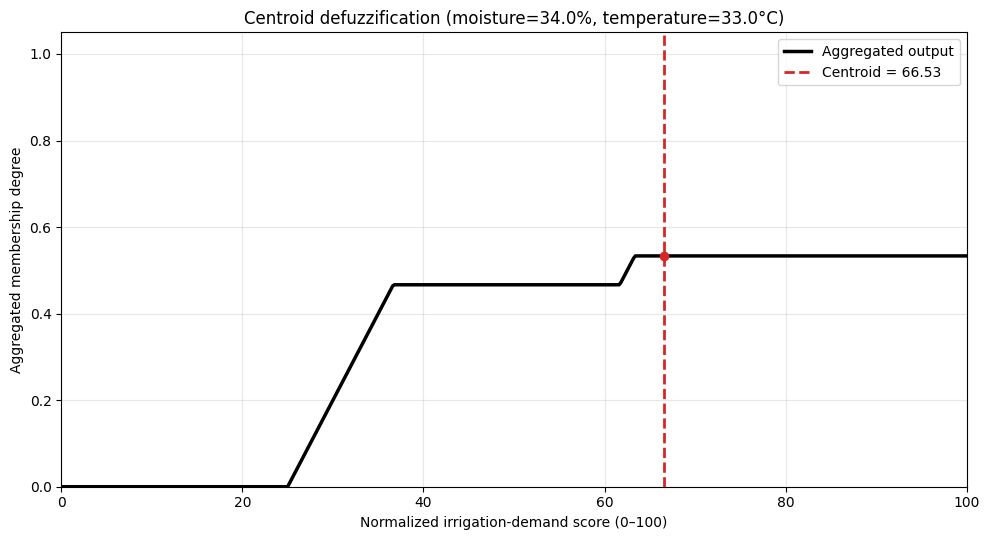

Worked example (moisture=45%, temperature=20°C): irrigation-demand score = 49.71 / 100


In [ ]:
def centroid_defuzzify(output_grid, aggregated_membership):
    """Return a crisp output using the discrete centroid formula.

    The output grid is expected to be uniformly spaced, as demand_grid is.
    The uniform grid spacing cancels from the numerator and denominator.
    """
    x = np.asarray(output_grid, dtype=float)
    mu = np.asarray(aggregated_membership, dtype=float)

    if x.ndim != 1 or mu.ndim != 1:
        raise ValueError("Output grid and aggregated membership must be 1-D arrays.")
    if x.shape != mu.shape:
        raise ValueError("Output grid and aggregated membership must have the same shape.")
    if x.size < 2:
        raise ValueError("At least two output-grid points are required.")
    if not np.all(np.isfinite(x)) or not np.all(np.isfinite(mu)):
        raise ValueError("Output grid and membership values must be finite.")
    if np.any(np.diff(x) <= 0):
        raise ValueError("Output grid must be strictly increasing.")
    if np.any((mu < 0.0) | (mu > 1.0)):
        raise ValueError("Aggregated membership degrees must lie in [0, 1].")

    denominator = float(np.sum(mu))
    if denominator <= 0.0:
        raise ValueError(
            "Cannot defuzzify: aggregated output has zero membership everywhere."
        )

    numerator = float(np.sum(x * mu))
    crisp_output = numerator / denominator

    # Guard against unexpected numerical issues.
    if not np.isfinite(crisp_output):
        raise ValueError("Centroid calculation produced a non-finite result.")
    if crisp_output < x[0] - 1e-9 or crisp_output > x[-1] + 1e-9:
        raise ValueError("Centroid lies outside the output universe.")

    return crisp_output


def plot_centroid(output_grid, aggregated_membership, crisp_output, title):
    """Plot the aggregated output and mark its discrete centroid."""
    plt.figure(figsize=(10, 5.5))
    plt.plot(
        output_grid, aggregated_membership,
        color="black", linewidth=2.5, label="Aggregated output"
    )
    plt.axvline(
        crisp_output, color="tab:red", linestyle="--", linewidth=2,
        label=f"Centroid = {crisp_output:.2f}"
    )
    plt.scatter(
        [crisp_output], [np.interp(crisp_output, output_grid, aggregated_membership)],
        color="tab:red", zorder=5
    )
    plt.title(title)
    plt.xlabel("Normalized irrigation-demand score (0–100)")
    plt.ylabel("Aggregated membership degree")
    plt.xlim(DEMAND_MIN, DEMAND_MAX)
    plt.ylim(0.0, 1.05)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


# Phase 4: defuzzify the current user-input example.
irrigation_demand_score = centroid_defuzzify(demand_grid, aggregated_output)
print(f"Crisp irrigation-demand score: {irrigation_demand_score:.2f} / 100")
plot_centroid(
    demand_grid,
    aggregated_output,
    irrigation_demand_score,
    title=(
        "Centroid defuzzification "
        f"(moisture={soil_moisture_input:.1f}%, "
        f"temperature={temperature_input:.1f}°C)"
    ),
)

# Also calculate the same worked example used in Phases 2–3 (45%, 20°C).
example_centroid = centroid_defuzzify(demand_grid, example_aggregated_output)
print(
    "Worked example (moisture=45%, temperature=20°C): "
    f"irrigation-demand score = {example_centroid:.2f} / 100"
)


In [ ]:
# Phase 4 tests: verify centroid calculation and error handling.

# The crisp score must be finite and inside the defined output range.
assert np.isfinite(irrigation_demand_score)
assert DEMAND_MIN <= irrigation_demand_score <= DEMAND_MAX

# Independent calculation of the discrete centroid for the worked example.
manual_example_centroid = (
    np.sum(demand_grid * example_aggregated_output)
    / np.sum(example_aggregated_output)
)
assert np.isclose(example_centroid, manual_example_centroid)

# A symmetric triangular membership curve should have its centroid at its center.
symmetric_test_grid = np.linspace(0.0, 100.0, 1001)
symmetric_test_curve = trimf(symmetric_test_grid, 20.0, 50.0, 80.0)
symmetric_test_centroid = centroid_defuzzify(
    symmetric_test_grid, symmetric_test_curve
)
assert np.isclose(symmetric_test_centroid, 50.0, atol=0.1)

# Zero aggregate must raise a clear error rather than returning an arbitrary score.
try:
    centroid_defuzzify(demand_grid, np.zeros_like(demand_grid))
except ValueError as exc:
    assert "zero membership" in str(exc)
else:
    raise AssertionError("Zero aggregate should raise ValueError.")

print("All Phase 4 tests passed.")



All Phase 4 tests passed.



--- Scenario comparison: fuzzy controller vs threshold baseline ---
Scenario               Moisture  Temp °C  Fuzzy score Fuzzy label     Baseline  Baseline decision Fuzzy − baseline
--------------------------------------------------------------------------------------------------------------------
Very dry and hot            5.0     40.0        80.61 High               100.0  Irrigate                    -19.39
Very wet and cool          95.0     10.0         8.27 None/very low        0.0  Do not irrigate               8.27
Moderate conditions        40.0     25.0        60.79 Medium               0.0  Do not irrigate              60.79
Dry and cool               10.0     10.0        50.00 Medium             100.0  Irrigate                    -50.00
Wet and hot                90.0     40.0        25.00 Low                  0.0  Do not irrigate              25.00
Near breakpoint            30.0     22.0        68.81 High                 0.0  Do not irrigate              68.81


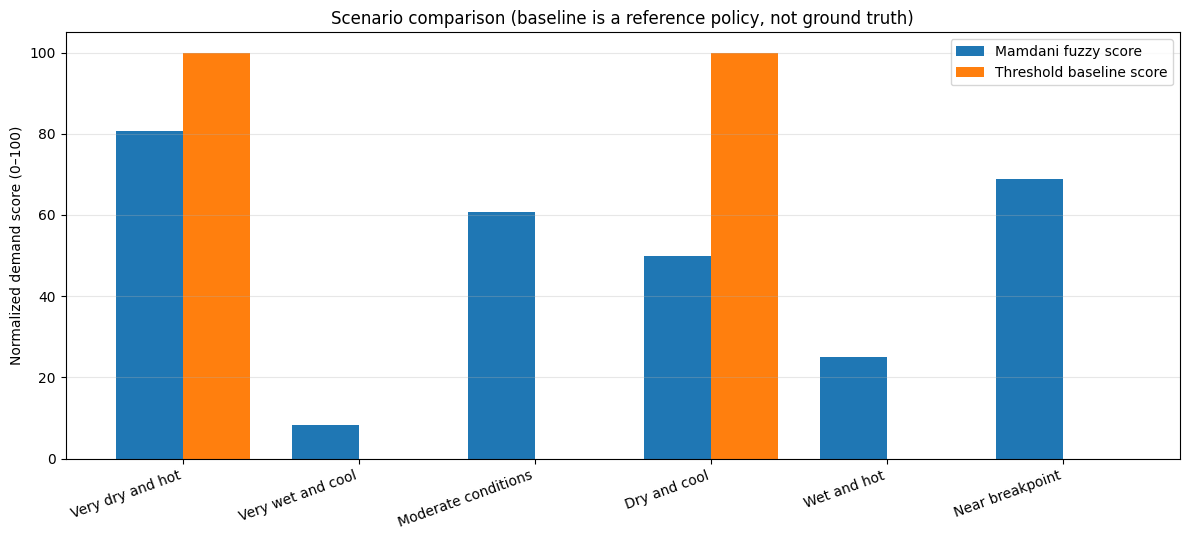

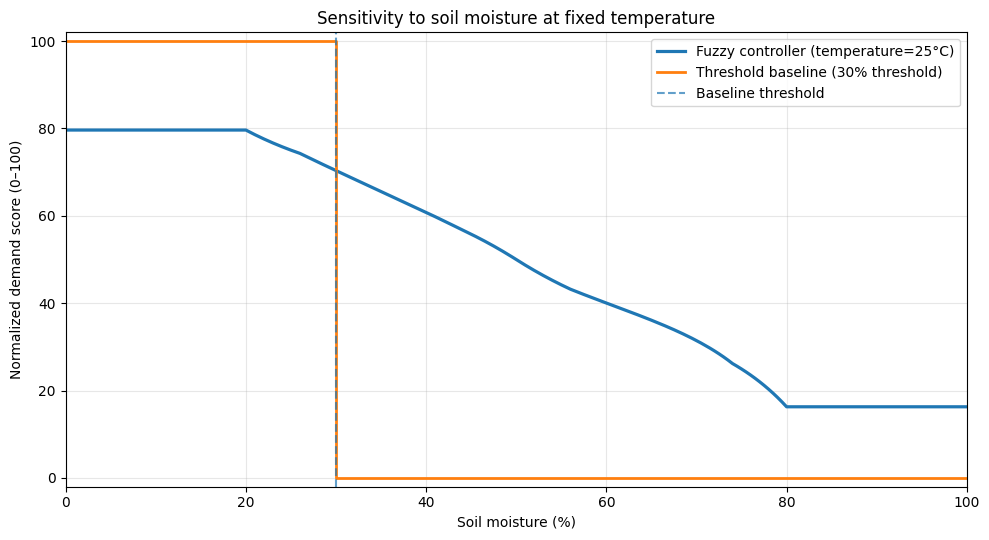

Scenario results saved to: smart_irrigation_phase5_comparison.csv

--- Phase 5 descriptive evaluation summary ---
Scenarios evaluated: 6
Decision disagreements (fuzzy score threshold 50 vs crisp baseline): 2
Mean absolute score difference (descriptive only): 38.71
The score difference is NOT MAE against ground truth. The 50-point fuzzy decision cutoff is a stated prototype assumption.
All Phase 5 tests passed. Results describe behavior, not accuracy or proven water savings.


In [ ]:
 # Phase 5: baseline comparison and scenario evaluation.
# Reuse the tested Phase 1–4 functions; do not reimplement fuzzy inference here.

BASELINE_MOISTURE_THRESHOLD = 30.0  # Prototype assumption, not crop-calibrated.


def threshold_baseline(soil_moisture, threshold=BASELINE_MOISTURE_THRESHOLD):
    """Simple crisp baseline: 100 if moisture < threshold, otherwise 0.

    The threshold is a comparison policy, not a validated irrigation recommendation.
    Temperature is deliberately ignored by this baseline.
    """
    moisture = parse_bounded_float(
        soil_moisture, "Soil moisture", MOISTURE_MIN, MOISTURE_MAX
    )
    threshold = parse_bounded_float(
        threshold, "Baseline threshold", MOISTURE_MIN, MOISTURE_MAX
    )
    return 100.0 if moisture < threshold else 0.0


def interpret_demand_score(score):
    """Convert a crisp score to a readable label using display-only bands."""
    value = parse_bounded_float(score, "Demand score", DEMAND_MIN, DEMAND_MAX)
    if value <= 10.0:
        return "None/very low"
    if value <= 35.0:
        return "Low"
    if value <= 65.0:
        return "Medium"
    return "High"


def run_fuzzy_controller(soil_moisture, temperature):
    """Run fuzzification → rule evaluation → implication → aggregation → centroid."""
    moisture = parse_bounded_float(
        soil_moisture, "Soil moisture", MOISTURE_MIN, MOISTURE_MAX
    )
    temp = parse_bounded_float(
        temperature, "Temperature", TEMPERATURE_MIN, TEMPERATURE_MAX
    )
    moisture_degrees = fuzzify(moisture_mfs, moisture)
    temperature_degrees = fuzzify(temperature_mfs, temp)
    rules = evaluate_rule_strengths(moisture_degrees, temperature_degrees)
    clipped = apply_mamdani_implication(rules, demand_sets, demand_grid)
    aggregate = aggregate_rule_outputs(clipped)
    score = centroid_defuzzify(demand_grid, aggregate)
    return {
        "soil_moisture": moisture,
        "temperature": temp,
        "moisture_memberships": moisture_degrees,
        "temperature_memberships": temperature_degrees,
        "rule_results": rules,
        "clipped_outputs": clipped,
        "aggregated_output": aggregate,
        "fuzzy_score": score,
        "fuzzy_label": interpret_demand_score(score),
    }


# Scenarios from the project workflow plus one overlap/breakpoint case.
EVALUATION_SCENARIOS = [
    {"scenario": "Very dry and hot", "moisture": 5.0, "temperature": 40.0},
    {"scenario": "Very wet and cool", "moisture": 95.0, "temperature": 10.0},
    {"scenario": "Moderate conditions", "moisture": 40.0, "temperature": 25.0},
    {"scenario": "Dry and cool", "moisture": 10.0, "temperature": 10.0},
    {"scenario": "Wet and hot", "moisture": 90.0, "temperature": 40.0},
    {"scenario": "Near breakpoint", "moisture": 30.0, "temperature": 22.0},
]


def compare_scenarios(scenarios):
    """Run the fuzzy model and crisp baseline on identical scenarios."""
    rows = []
    for scenario in scenarios:
        result = run_fuzzy_controller(scenario["moisture"], scenario["temperature"])
        baseline_score = threshold_baseline(scenario["moisture"])
        baseline_decision = "Irrigate" if baseline_score == 100.0 else "Do not irrigate"
        rows.append({
            "scenario": scenario["scenario"],
            "moisture_percent": scenario["moisture"],
            "temperature_c": scenario["temperature"],
            "fuzzy_score": result["fuzzy_score"],
            "fuzzy_label": result["fuzzy_label"],
            "baseline_score": baseline_score,
            "baseline_decision": baseline_decision,
            "score_difference_fuzzy_minus_baseline": result["fuzzy_score"] - baseline_score,
        })
    return rows


def print_comparison_table(rows):
    """Print scenario results in a compact, dependency-free table."""
    headers = (
        "Scenario", "Moisture", "Temp °C", "Fuzzy score", "Fuzzy label",
        "Baseline", "Baseline decision", "Fuzzy − baseline"
    )
    print("\n--- Scenario comparison: fuzzy controller vs threshold baseline ---")
    print(
        f"{headers[0]:<22} {headers[1]:>8} {headers[2]:>8} {headers[3]:>12} "
        f"{headers[4]:<15} {headers[5]:>8}  {headers[6]:<17} {headers[7]:>16}"
    )
    print("-" * 116)
    for row in rows:
        print(
            f"{row['scenario']:<22} {row['moisture_percent']:>8.1f} "
            f"{row['temperature_c']:>8.1f} {row['fuzzy_score']:>12.2f} "
            f"{row['fuzzy_label']:<15} {row['baseline_score']:>8.1f}  "
            f"{row['baseline_decision']:<17} "
            f"{row['score_difference_fuzzy_minus_baseline']:>16.2f}"
        )


def plot_scenario_comparison(rows):
    """Plot fuzzy and threshold scores for the same predefined scenarios."""
    labels = [row["scenario"] for row in rows]
    fuzzy_scores = [row["fuzzy_score"] for row in rows]
    baseline_scores = [row["baseline_score"] for row in rows]
    positions = np.arange(len(rows))
    width = 0.38

    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.bar(positions - width / 2, fuzzy_scores, width, label="Mamdani fuzzy score")
    ax.bar(positions + width / 2, baseline_scores, width, label="Threshold baseline score")
    ax.set_xticks(positions)
    ax.set_xticklabels(labels, rotation=20, ha="right")
    ax.set_ylabel("Normalized demand score (0–100)")
    ax.set_ylim(0, 105)
    ax.set_title("Scenario comparison (baseline is a reference policy, not ground truth)")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    plt.show()


def plot_moisture_sensitivity(temperature=25.0):
    """Sweep moisture and compare the fuzzy response with the crisp baseline."""
    temp = parse_bounded_float(
        temperature, "Temperature", TEMPERATURE_MIN, TEMPERATURE_MAX
    )
    moisture_values = np.linspace(MOISTURE_MIN, MOISTURE_MAX, 201)
    fuzzy_values = [run_fuzzy_controller(m, temp)["fuzzy_score"] for m in moisture_values]
    baseline_values = [threshold_baseline(m) for m in moisture_values]

    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.plot(moisture_values, fuzzy_values, label=f"Fuzzy controller (temperature={temp:g}°C)", linewidth=2.3)
    ax.step(moisture_values, baseline_values, where="post", label="Threshold baseline (30% threshold)", linewidth=2)
    ax.axvline(BASELINE_MOISTURE_THRESHOLD, linestyle="--", alpha=0.7, label="Baseline threshold")
    ax.set_xlabel("Soil moisture (%)")
    ax.set_ylabel("Normalized demand score (0–100)")
    ax.set_xlim(MOISTURE_MIN, MOISTURE_MAX)
    ax.set_ylim(-2, 102)
    ax.set_title("Sensitivity to soil moisture at fixed temperature")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    plt.show()
    return moisture_values, np.asarray(fuzzy_values), np.asarray(baseline_values)


# Run the fixed evaluation scenarios.
evaluation_rows = compare_scenarios(EVALUATION_SCENARIOS)
print_comparison_table(evaluation_rows)
plot_scenario_comparison(evaluation_rows)

# Sensitivity experiment: change moisture while holding temperature fixed.
sensitivity_moisture, sensitivity_fuzzy, sensitivity_baseline = plot_moisture_sensitivity(
    temperature=25.0
)

# Save the actual scenario results so the report can use reproducible outputs.
import csv
RESULTS_CSV = "smart_irrigation_phase5_comparison.csv"
with open(RESULTS_CSV, "w", newline="", encoding="utf-8") as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=list(evaluation_rows[0].keys()))
    writer.writeheader()
    writer.writerows(evaluation_rows)
print(f"Scenario results saved to: {RESULTS_CSV}")

# Phase 5: transparent descriptive evaluation (not accuracy scoring).
# No trusted target labels or field measurements are available, so MAE/RMSE/accuracy
# would be unjustified. We report policy disagreement and score differences only.
for row in evaluation_rows:
    row["baseline_decision"] = "Irrigate" if row["baseline_score"] == 100.0 else "Do not irrigate"
    row["fuzzy_decision_at_50"] = "Irrigate" if row["fuzzy_score"] >= 50.0 else "Do not irrigate"
    row["decision_disagreement"] = row["baseline_decision"] != row["fuzzy_decision_at_50"]
    row["absolute_score_difference"] = abs(row["fuzzy_score"] - row["baseline_score"])

# Re-save the enriched comparison table.
with open(RESULTS_CSV, "w", newline="", encoding="utf-8") as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=list(evaluation_rows[0].keys()))
    writer.writeheader()
    writer.writerows(evaluation_rows)

# Phase 5 validation tests.
assert len(evaluation_rows) == len(EVALUATION_SCENARIOS)
assert all(np.isfinite(row["fuzzy_score"]) for row in evaluation_rows)
assert all(DEMAND_MIN <= row["fuzzy_score"] <= DEMAND_MAX for row in evaluation_rows)
assert all(row["baseline_score"] in (0.0, 100.0) for row in evaluation_rows)
assert threshold_baseline(29.999) == 100.0
assert threshold_baseline(30.0) == 0.0
assert threshold_baseline(100.0) == 0.0
assert np.all(np.isfinite(sensitivity_fuzzy))
assert np.all((sensitivity_fuzzy >= DEMAND_MIN) & (sensitivity_fuzzy <= DEMAND_MAX))
assert np.all(np.isfinite(sensitivity_baseline))
assert all(isinstance(row["decision_disagreement"], bool) for row in evaluation_rows)
assert all(row["absolute_score_difference"] >= 0.0 for row in evaluation_rows)

repeat_a = run_fuzzy_controller(45.0, 20.0)["fuzzy_score"]
repeat_b = run_fuzzy_controller(45.0, 20.0)["fuzzy_score"]
assert np.isclose(repeat_a, repeat_b)

print("\n--- Phase 5 descriptive evaluation summary ---")
print(f"Scenarios evaluated: {len(evaluation_rows)}")
print(f"Decision disagreements (fuzzy score threshold 50 vs crisp baseline): {sum(r['decision_disagreement'] for r in evaluation_rows)}")
print(f"Mean absolute score difference (descriptive only): {np.mean([r['absolute_score_difference'] for r in evaluation_rows]):.2f}")
print("The score difference is NOT MAE against ground truth. The 50-point fuzzy decision cutoff is a stated prototype assumption.")
print("All Phase 5 tests passed. Results describe behavior, not accuracy or proven water savings.")



--- Phase 6 final validation ---
Grid points tested: 2,346
Minimum score on grid: 8.27
Maximum score on grid: 80.61
All sampled scores are finite and inside [0, 100].
Soil-moisture monotonicity violations at fixed temperature: 0

Temperature-response diagnostic (decreases are reported, not silently ignored):
  Moisture   0.0%: 6 temperature-step decrease(s); first begins near 23.0°C; largest step change -0.436
  Moisture  20.0%: 6 temperature-step decrease(s); first begins near 23.0°C; largest step change -0.436
  Moisture  40.0%: 2 temperature-step decrease(s); first begins near 29.0°C; largest step change -0.681
  Moisture  60.0%: 6 temperature-step decrease(s); first begins near 23.0°C; largest step change -0.586
  Moisture  80.0%: 6 temperature-step decrease(s); first begins near 16.0°C; largest step change -0.327
  Moisture 100.0%: 6 temperature-step decrease(s); first begins near 16.0°C; largest step change -0.327
REVIEW NOTE: The current temperature response is not monotonic for

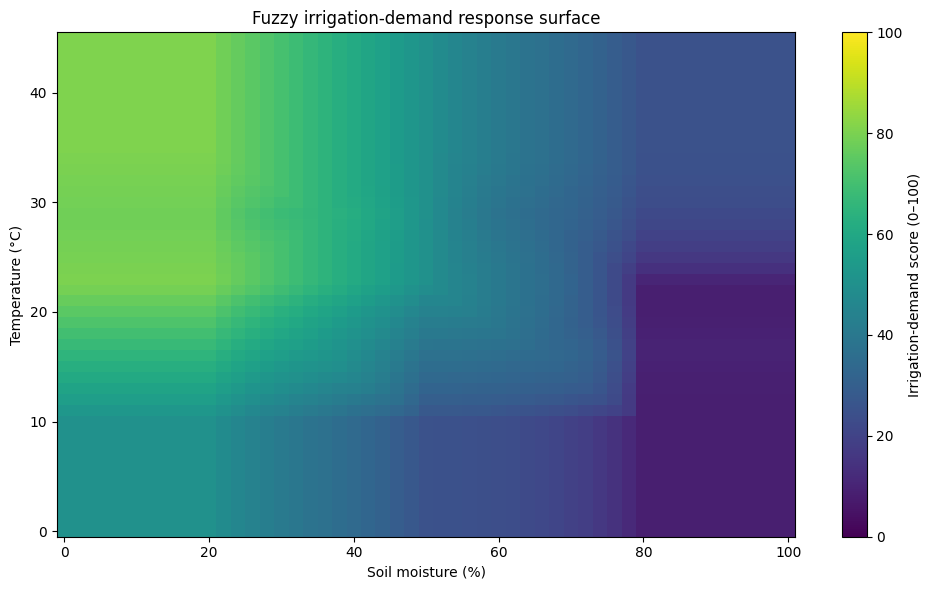

Response-surface data saved to: smart_irrigation_phase6_surface.csv
Endpoint cases checked: 5
Invalid-input cases correctly rejected: 6
Zero-strength rule contributes a zero output curve: passed
All Phase 6 hard validation checks passed.
Reminder: these are model-consistency checks, not field validation or proof of water savings.


In [ ]:
  # Phase 6: grid-based final validation and response-surface visualization.
# Reuses the Phase 1-5 controller without changing the model parameters or rules.

VALIDATION_MOISTURE_GRID = np.linspace(MOISTURE_MIN, MOISTURE_MAX, 51)  # 2% increments
VALIDATION_TEMPERATURE_GRID = np.linspace(TEMPERATURE_MIN, TEMPERATURE_MAX, 46)  # 1°C increments

# Rows are temperatures; columns are soil-moisture values.
score_surface = np.empty(
    (len(VALIDATION_TEMPERATURE_GRID), len(VALIDATION_MOISTURE_GRID)),
    dtype=float,
)

for ti, temp_value in enumerate(VALIDATION_TEMPERATURE_GRID):
    for mi, moisture_value in enumerate(VALIDATION_MOISTURE_GRID):
        score_surface[ti, mi] = run_fuzzy_controller(
            moisture_value, temp_value
        )["fuzzy_score"]

# Broad validity checks across the sampled 2D input domain.
assert score_surface.shape == (
    len(VALIDATION_TEMPERATURE_GRID), len(VALIDATION_MOISTURE_GRID)
)
assert np.all(np.isfinite(score_surface)), "Non-finite score found on the validation grid."
assert np.all((score_surface >= DEMAND_MIN) & (score_surface <= DEMAND_MAX)), (
    "Score outside the output universe found on the validation grid."
)

# Under the current rule table, demand should not rise as soil moisture rises,
# holding temperature fixed. Test this behavior over the sampled grid.
moisture_differences = np.diff(score_surface, axis=1)
MOISTURE_MONOTONICITY_TOLERANCE = 1e-7
moisture_monotonicity_violations = int(
    np.count_nonzero(moisture_differences > MOISTURE_MONOTONICITY_TOLERANCE)
)
assert moisture_monotonicity_violations == 0, (
    "Demand increased at one or more sampled points when moisture increased. "
    "Review the rule base and membership functions."
)

# Temperature is analyzed diagnostically rather than asserted as monotonic.
# Reason: the present Warm triangular MF and Hot right-shoulder MF overlap, while
# nearby rules can share a consequent; max aggregation may expose a local dip.
DIAGNOSTIC_MOISTURE_VALUES = [0.0, 20.0, 40.0, 60.0, 80.0, 100.0]
temperature_diagnostic = []
for moisture_value in DIAGNOSTIC_MOISTURE_VALUES:
    temperature_scores = np.array([
        run_fuzzy_controller(moisture_value, temp_value)["fuzzy_score"]
        for temp_value in VALIDATION_TEMPERATURE_GRID
    ])
    differences = np.diff(temperature_scores)
    decrease_indices = np.flatnonzero(differences < -MOISTURE_MONOTONICITY_TOLERANCE)
    temperature_diagnostic.append({
        "moisture": moisture_value,
        "temperature_scores": temperature_scores,
        "decrease_count": int(len(decrease_indices)),
        "first_decrease_from_c": (
            float(VALIDATION_TEMPERATURE_GRID[decrease_indices[0]])
            if len(decrease_indices) else None
        ),
        "min_step_change": float(differences.min()) if len(differences) else 0.0,
    })

temperature_decrease_count = sum(
    item["decrease_count"] for item in temperature_diagnostic
)

print("--- Phase 6 final validation ---")
print(f"Grid points tested: {score_surface.size:,}")
print(f"Minimum score on grid: {score_surface.min():.2f}")
print(f"Maximum score on grid: {score_surface.max():.2f}")
print("All sampled scores are finite and inside [0, 100].")
print(
    "Soil-moisture monotonicity violations at fixed temperature: "
    f"{moisture_monotonicity_violations}"
)
print("\nTemperature-response diagnostic (decreases are reported, not silently ignored):")
for item in temperature_diagnostic:
    if item["decrease_count"]:
        print(
            f"  Moisture {item['moisture']:>5.1f}%: "
            f"{item['decrease_count']} temperature-step decrease(s); "
            f"first begins near {item['first_decrease_from_c']:.1f}°C; "
            f"largest step change {item['min_step_change']:.3f}"
        )
    else:
        print(f"  Moisture {item['moisture']:>5.1f}%: no decrease on the sampled temperature grid")

if temperature_decrease_count:
    print(
        "REVIEW NOTE: The current temperature response is not monotonic for all sampled "
        "moisture values. This is a rule/membership-design behavior to inspect before "
        "the final presentation; it is not a Python execution error."
    )
else:
    print("No temperature-response decreases found in the selected diagnostic slices.")

# Explicit endpoint checks: outputs must be finite and bounded at all domain corners.
ENDPOINT_CASES = [
    (MOISTURE_MIN, TEMPERATURE_MIN),
    (MOISTURE_MIN, TEMPERATURE_MAX),
    (MOISTURE_MAX, TEMPERATURE_MIN),
    (MOISTURE_MAX, TEMPERATURE_MAX),
    (30.0, 22.5),  # membership overlap/breakpoint
]
for endpoint_moisture, endpoint_temperature in ENDPOINT_CASES:
    endpoint_score = run_fuzzy_controller(endpoint_moisture, endpoint_temperature)["fuzzy_score"]
    assert np.isfinite(endpoint_score)
    assert DEMAND_MIN <= endpoint_score <= DEMAND_MAX

# Invalid inputs must be rejected instead of silently clipped or accepted.
INVALID_INPUT_CASES = [
    (-1.0, 20.0), (101.0, 20.0), (45.0, -0.1), (45.0, 45.1),
    ("not-a-number", 20.0), (45.0, float("nan")),
]
for bad_moisture, bad_temperature in INVALID_INPUT_CASES:
    try:
        run_fuzzy_controller(bad_moisture, bad_temperature)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Invalid input was not rejected: {(bad_moisture, bad_temperature)}")

# A rule with zero firing strength must contribute an all-zero clipped output.
zero_rule = {"rule_id": "TEST_ZERO", "firing_strength": 0.0, "demand_term": "High"}
zero_curve = apply_mamdani_implication([zero_rule], demand_sets, demand_grid)["TEST_ZERO"]
assert np.allclose(zero_curve, 0.0)

# Response-surface heatmap: a useful summary visual for the report/viva.
fig, ax = plt.subplots(figsize=(10, 6))
mesh = ax.pcolormesh(
    VALIDATION_MOISTURE_GRID,
    VALIDATION_TEMPERATURE_GRID,
    score_surface,
    shading="auto",
    vmin=DEMAND_MIN,
    vmax=DEMAND_MAX,
)
fig.colorbar(mesh, ax=ax, label="Irrigation-demand score (0–100)")
ax.set_xlabel("Soil moisture (%)")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Fuzzy irrigation-demand response surface")
fig.tight_layout()
plt.show()

# Save raw surface values so all response-surface results can be reproduced.
import csv
PHASE6_SURFACE_CSV = "smart_irrigation_phase6_surface.csv"
with open(PHASE6_SURFACE_CSV, "w", newline="", encoding="utf-8") as surface_file:
    writer = csv.writer(surface_file)
    writer.writerow(["temperature_c", "soil_moisture_percent", "fuzzy_demand_score"])
    for ti, temp_value in enumerate(VALIDATION_TEMPERATURE_GRID):
        for mi, moisture_value in enumerate(VALIDATION_MOISTURE_GRID):
            writer.writerow([
                float(temp_value),
                float(moisture_value),
                float(score_surface[ti, mi]),
            ])
print(f"Response-surface data saved to: {PHASE6_SURFACE_CSV}")

# Repeatability check on a representative non-boundary input.
validation_repeat_1 = run_fuzzy_controller(45.0, 20.0)["fuzzy_score"]
validation_repeat_2 = run_fuzzy_controller(45.0, 20.0)["fuzzy_score"]
assert np.isclose(validation_repeat_1, validation_repeat_2)

# Comparative sanity scenario: very dry/hot should demand more than very wet/cool.
dry_hot_score = run_fuzzy_controller(5.0, 40.0)["fuzzy_score"]
wet_cool_score = run_fuzzy_controller(95.0, 10.0)["fuzzy_score"]
assert dry_hot_score > wet_cool_score

print(f"Endpoint cases checked: {len(ENDPOINT_CASES)}")
print(f"Invalid-input cases correctly rejected: {len(INVALID_INPUT_CASES)}")
print("Zero-strength rule contributes a zero output curve: passed")
print("All Phase 6 hard validation checks passed.")
print("Reminder: these are model-consistency checks, not field validation or proof of water savings.")

In [ ]:

# ============================================================
# SMART IRRIGATION - INTERACTIVE DEMONSTRATION
# Uses the existing Mamdani fuzzy logic controller.
# ============================================================

import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import numpy as np

# Input controls
moisture_slider = widgets.IntSlider(
    value=45,
    min=0,
    max=100,
    step=1,
    description="Moisture:",
    style={"description_width": "initial"},
    continuous_update=False
)

temperature_slider = widgets.FloatSlider(
    value=20,
    min=0,
    max=45,
    step=0.5,
    description="Temperature:",
    style={"description_width": "initial"},
    continuous_update=False
)

output_area = widgets.Output()

def update_dashboard(moisture, temperature):

    with output_area:
        clear_output(wait=True)

        # Run the existing fuzzy controller
        result = run_fuzzy_controller(moisture, temperature)

        print("=" * 55)
        print("       SMART IRRIGATION SYSTEM")
        print("=" * 55)

        print(f"\nSoil Moisture: {moisture}%")
        print(f"Temperature: {temperature} °C")

        # 1. Final irrigation score
        print("\n1. FINAL IRRIGATION DEMAND")
        print("-" * 35)
        print(f"Demand Score: {result['fuzzy_score']:.2f} / 100")
        print(f"Demand Category: {result['fuzzy_label']}")

        # 2. Membership degrees
        print("\n2. MOISTURE MEMBERSHIP DEGREES")
        print("-" * 35)
        for name, degree in result["moisture_memberships"].items():
            print(f"{name:<12}: {degree:.3f}")

        print("\n3. TEMPERATURE MEMBERSHIP DEGREES")
        print("-" * 35)
        for name, degree in result["temperature_memberships"].items():
            print(f"{name:<12}: {degree:.3f}")

        # 4. Activated rules
        print("\n4. ACTIVATED FUZZY RULES")
        print("-" * 35)

        active_rules = [
            rule for rule in result["rule_results"]
            if rule["firing_strength"] > 0
        ]

        if active_rules:
            for rule in active_rules:
                print(
                    f"{rule['rule_id']}: "
                    f"Strength = {rule['firing_strength']:.3f}, "
                    f"Output = {rule['demand_term']}"
                )
        else:
            print("No rules activated.")

        print(f"\nActive rules: {len(active_rules)} / 9")

        # 5. Aggregated output and centroid
        print("\n5. AGGREGATED OUTPUT AND CENTROID")
        print("-" * 35)

        aggregate = result["aggregated_output"]
        score = result["fuzzy_score"]

        fig, ax = plt.subplots(figsize=(9, 4))

        ax.plot(
            demand_grid,
            aggregate,
            label="Aggregated fuzzy output",
            linewidth=2
        )

        ax.fill_between(
            demand_grid,
            aggregate,
            alpha=0.25
        )

        ax.axvline(
            score,
            linestyle="--",
            linewidth=2,
            label=f"Centroid = {score:.2f}"
        )

        ax.set_title("Mamdani Aggregated Output")
        ax.set_xlabel("Irrigation Demand Score (0–100)")
        ax.set_ylabel("Membership Degree")
        ax.set_xlim(0, 100)
        ax.set_ylim(0, 1.05)
        ax.grid(True, alpha=0.3)
        ax.legend()

        plt.tight_layout()
        plt.show()

        print(f"Centroid defuzzified score: {score:.2f}")
        print("\nNote: This is a simulated demand score,")
        print("not a physical water quantity or pump duration.")

# Connect the sliders to the dashboard
dashboard = widgets.interactive_output(
    update_dashboard,
    {
        "moisture": moisture_slider,
        "temperature": temperature_slider
    }
)

display(
    widgets.VBox([
        widgets.HTML("<h2>Smart Irrigation Control Panel</h2>"),
        moisture_slider,
        temperature_slider,
        output_area
    ])
)

# Trigger the first display
update_dashboard(
    moisture_slider.value,
    temperature_slider.value
)
